Saving Mall_Customers.csv to Mall_Customers (6).csv
First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset shape:
(200, 5)

Columns:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age               

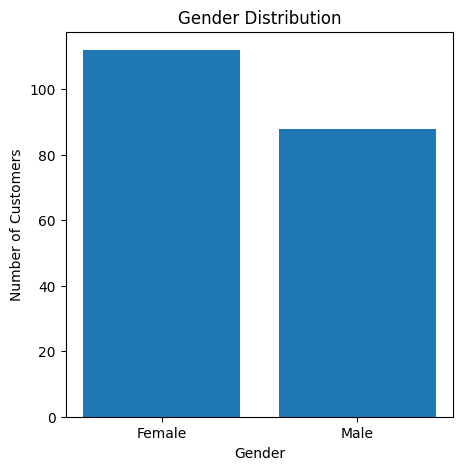

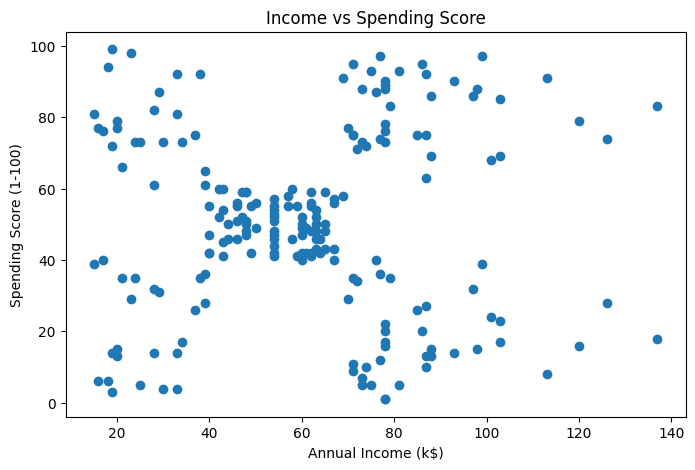


Scaled data mean:
[-2.13162821e-16 -1.46549439e-16]

Scaled data standard deviation:
[1. 1.]

WCSS values:
[399.99999999999994, 269.69101219276405, 157.70400815035939, 108.92131661364358, 65.56840815571681, 55.057348270385965, 44.86475569922555, 37.22818767758587, 32.39226763033118, 29.981897788243703]


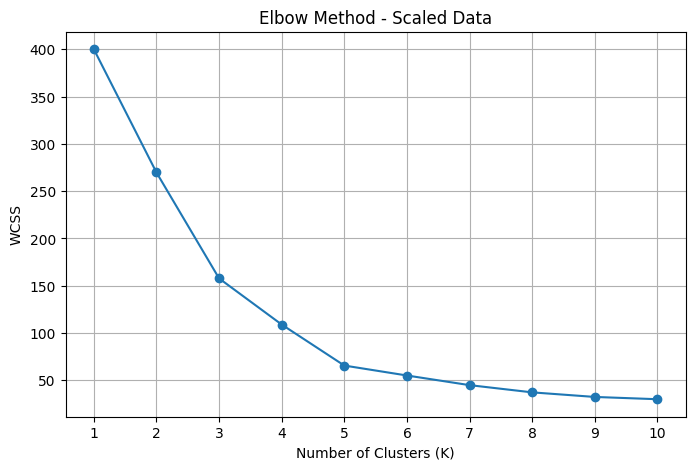

K=2, Silhouette Score=0.3213
K=3, Silhouette Score=0.4666
K=4, Silhouette Score=0.4939
K=5, Silhouette Score=0.5547
K=6, Silhouette Score=0.5399
K=7, Silhouette Score=0.5281
K=8, Silhouette Score=0.4552
K=9, Silhouette Score=0.4571
K=10, Silhouette Score=0.4432


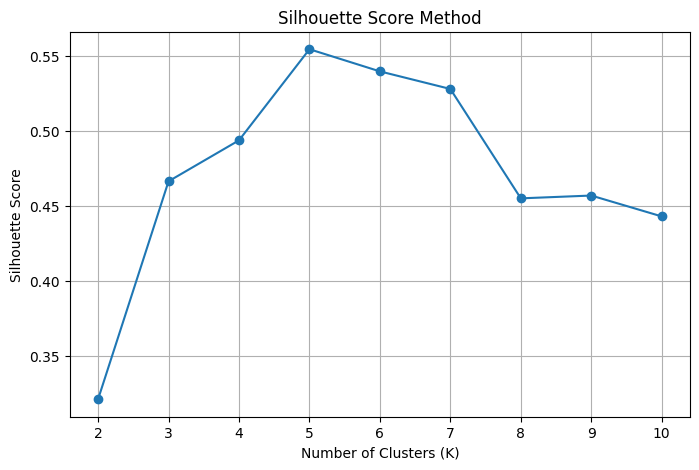

   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2

Cluster counts:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


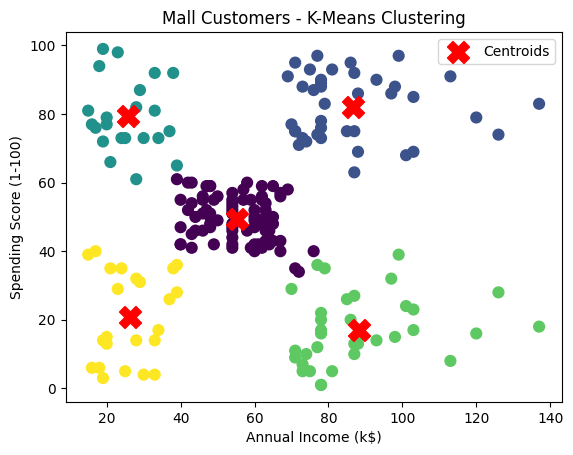

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
k_values = range(2, 11)
silhouette_scores = []

# 1. Upload dataset
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# 2. Load dataset
df = pd.read_csv(filename)

# 3. Explore dataset
print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe())

print("\nGender distribution:")
print(df["Gender"].value_counts())

# 4. Gender distribution graph
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(5, 5))
plt.bar(gender_counts.index, gender_counts.values)
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.title("Gender Distribution")
plt.show()

# 5. Income vs Spending Score scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Income vs Spending Score")
plt.show()

# 6. Select features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 7. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled data mean:")
print(X_scaled.mean(axis=0))

print("\nScaled data standard deviation:")
print(X_scaled.std(axis=0))

# 8. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

print("\nWCSS values:")
print(wcss)

# 9. Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method - Scaled Data")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

# Step 4: Graph banao
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()
final_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_scaled)

df["Cluster"] = final_labels

print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head(10))

print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=final_labels,
    cmap="viridis",
    s=60
)

# Centroids ko original scale par convert karo
centers = scaler.inverse_transform(final_model.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customers - K-Means Clustering")
plt.legend()
plt.show()